# One Memory, Every Assistant: Muse, Grok Bot and dots on the Same Memory

Your assistant knows your calendar, your inbox and how you take your
coffee. Ask it when your own shop's sale ends and it will search the web.

It isn't short of memory. Muse remembers you. Grok Bot remembers you.
ChatGPT remembers you, and so does every dot you've made. That's three
memories of *you* — each one private to the app that keeps it — and none
of them is the memory your business runs on. The assistant in your pocket
is the best-informed stranger your company has ever had.

**This notebook is about letting the assistant in.**

In Notebook 1 a plant shop's agents came to share one memory,
`fern-ember`. In Notebook 2 three coding harnesses joined it. Here we put
that memory behind a sign-in and connect a personal assistant to it, the
way Muse, Grok Bot and a dot connect to anything: as a **custom connector
over MCP**. We build a small stand-in assistant so every step of that
connection is visible. Then you swap the stand-in for the real three.

It is the last of three parts. The memory hasn't changed since Notebook 1.
Only who is reading it has.

## Key takeaways

- ***Your assistant's memory is about you. Your team's memory is about the work.*** *Connecting them doesn't merge them; it gives the assistant somewhere to look.*
- ***A connector is a URL and a sign-in.*** *Muse, Grok Bot and dots all add a remote MCP server the same way. There is no SDK to install in any of them.*
- ***The assistant lives in someone else's cloud.*** *So the memory needs a public HTTPS address — and a lock that doesn't depend on the address being secret.*
- ***You approve an app once, with a code only you can make.*** *The page is public. The pairing code isn't.*
- ***Keep the app to one memory.*** *A store holds drafts, experiments and old decisions. An assistant should see the one memory you meant.*
- ***Every save has a name on it.*** *What the assistant writes is labelled with the app that wrote it, and a read-only pairing writes nothing at all.*
- ***One note, three kinds of agent.*** *Something you tell your phone reaches a support agent and a coding harness, without being sent to either.*

## How this notebook is organised

Twelve short parts. Parts 2 to 8 run on your computer with no account
anywhere; Parts 9 and 10 are the steps you take to connect the real apps.

| Part | What happens | What you have at the end |
|---|---|---|
| **1 · The use case** | You, away from your desk, and three assistants that don't know your shop | The problem, and six terms for the fix |
| **2 · Setup** | The store from Notebooks 1 and 2 | The memory, ready to be served |
| **3 · The memory, behind a sign-in** | One command puts `fern-ember` on an MCP server | A URL an assistant can be given |
| **4 · What an assistant does when you add a connector** | A stand-in assistant signs in, step by step | A token, and no mystery about how it got one |
| **5 · The assistant reads** | It lists its tools and asks about the sale | The decision Mara made, on your phone |
| **6 · The assistant writes** | You tell it something from the road | A note in the shared memory, labelled |
| **7 · Back to the team** | Sam and a coding harness are asked about it | One note, read by three kinds of agent |
| **8 · Who is connected** | A read-only assistant; disconnecting one | Control you can demonstrate |
| **9 · Going public** | A tunnel, and the same command | An address the real apps can reach |
| **10 · Muse, Grok Bot and a dot** | The clicks for each, and what to expect | Three assistants on one memory |
| **11 · See it in the UI** | Connected apps and the shared memory page | The whole cast on one screen |
| **12 · Trade-offs** | What this exposes, and when not to | Practical guidance, and an FAQ |

Running it makes one agent turn and, if a harness is installed, one short
harness run. It takes under a minute.

# Part 1 · The use case

This part is the *why*. You'll see why three assistants that each
"remember" you still can't answer a question about your own business, and
get the six terms the rest of the notebook is built from. No code runs.

## ⭐ The use case: the owner is at the supplier's

You own **Fern & Ember**. It's late November and you're at the ceramics
supplier's warehouse, phone in hand. Two things happen in ten minutes:

1. The supplier asks **when your Spring Sale ends**, to time a delivery.
   You know Mara decided it. You don't remember what she changed it to.
2. The supplier confirms **200 extra pots will arrive on 1 March**. Sam,
   your support agent, will be asked about pot stock all through the
   sale. He should know. So should whoever touches the stock code.

You have Muse on your phone, Grok Bot on your laptop, and a dot you made
in ChatGPT. Each will happily take the question and the note.

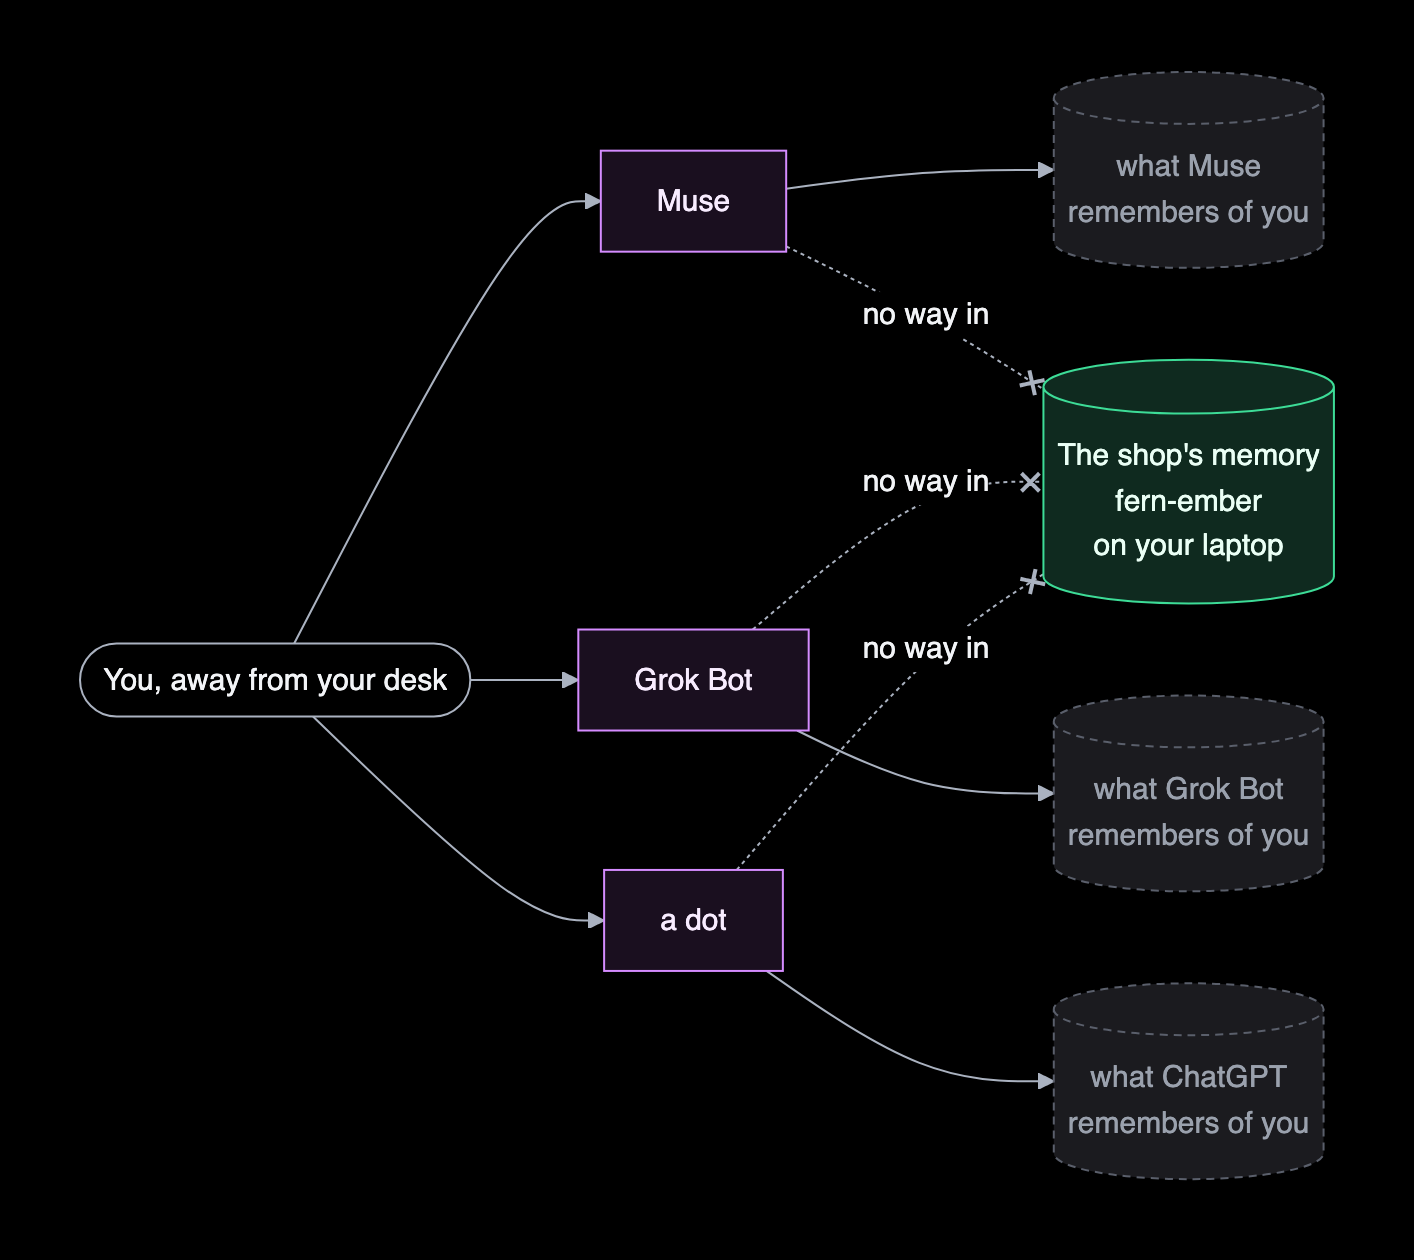

**How to read it.** Each assistant keeps a memory, and it is a memory of
*you*, inside that app. The shop's memory is on your laptop, where your
agents and harnesses use it. Ask Muse about the sale and it has nothing to
retrieve. Tell it about the pots and the note goes into Muse — where Sam
will never look.

## The fixes people reach for first

- **Tell the assistant yourself.** Paste the offer into Muse's memory.
  Now there are two copies of a decision, and the one in your pocket is
  the one nobody updates. (Mara already changed the end date once.)
- **Use the assistant's own memory as the team's.** Three assistants,
  three vendors, three memories, none of which your agents can read. You
  have rebuilt Notebook 1's problem with nicer icons.
- **Export and import.** A weekly paste from one to another. It is
  correct on Monday.

Each of these moves the team's knowledge *into* an app. The assistant
doesn't need a copy of the shop's memory. It needs a way to ask it.

> An assistant with your team's memory in it is a second source of truth.
> An assistant with a door to your team's memory is a colleague.

## ⭐ Six terms, defined once

- **A personal assistant is an agent that works for one person across
  their apps, usually from a vendor's cloud.** Muse (Meta), Grok Bot (xAI)
  and dots (OpenAI) are three. You don't run them; you configure them.
- **A connector is how an assistant reaches a system it wasn't built
  with.** All three accept a *custom* connector: you give a URL, the
  assistant finds out what it can do there.
- **MCP (Model Context Protocol) is the protocol a connector speaks.**
  A *remote MCP server* offers tools over HTTPS; the assistant lists them
  and calls them like any other tool.
- **OAuth is the sign-in between the assistant and the server.** The
  assistant never sees a password or a long-lived key. It gets a token for
  this one server, which you can take back.
- **A pairing code is your proof on the approval page.** It is made on
  your computer, works once, and expires in ten minutes. It's what stops a
  stranger who finds the address from approving themselves.
- **A public address is an HTTPS URL that reaches a server on your
  computer**, usually through a tunnel. The assistants call from their
  clouds, so `localhost` means nothing to them.

The store, the memory ID and the agents are exactly as Notebooks 1 and 2
left them.

# Part 2 · Setup

In this part we open the store the first two notebooks wrote. By the end
you'll have the memory in hand and have checked the record is there.

**Before you run it**

- Run **Notebook 1** first (and Notebook 2, if you'd like the assistant to
  find what the harnesses did).
- Use **MemoRizz 0.17.27 or later**: keeping apps to one memory
  (`--memory-id`) arrived in that release. Upgrade an older install with
  `pip install -U "memorizz[ui,filesystem,mcp]"`.

In [1]:
import atexit
import base64
import hashlib
import importlib.util
import json
import logging
import os
import secrets
import socket
import subprocess
import sys
import textwrap
import time
from pathlib import Path
from urllib.parse import parse_qs, urlparse

if importlib.util.find_spec("memorizz") is None:
    %pip install --quiet "memorizz[ui,filesystem,mcp]>=0.17.27"

In [2]:
if not os.getenv("OPENAI_API_KEY"):
    from dotenv import dotenv_values, find_dotenv

    os.environ["OPENAI_API_KEY"] = (
        dotenv_values(find_dotenv(usecwd=True)).get("OPENAI_API_KEY") or ""
    )
assert os.environ["OPENAI_API_KEY"], "Set OPENAI_API_KEY before running this notebook."

**The same store, the same memory ID**, opened the same way. As in
Notebook 2 there is no wipe here: this notebook adds to the shop's memory.

In [3]:
import memorizz
from memorizz import FileSystemConfig, FileSystemProvider, MemoryType

STORE = Path(os.getenv("MEMORIZZ_NB_STORE") or Path.cwd() / "fern_ember_store").resolve()
HOME = STORE.parent / "fern_ember_home"
os.environ["MEMORIZZ_HOME"] = str(HOME)
logging.disable(logging.WARNING)  # keep the lesson's output readable

EMBEDDING = {"model": "text-embedding-3-small", "dimensions": 256}
provider = FileSystemProvider(
    FileSystemConfig(root_path=STORE, embedding_provider="openai", embedding_config=EMBEDDING)
)
LLM = {"provider": "openai", "model": os.getenv("MEMORIZZ_NB_CHAT_MODEL", "gpt-6-luna")}
TEAM = "fern-ember"  # the memory ID from Notebooks 1 and 2
print("memorizz", memorizz.__version__, "| store:", STORE.name, "| memory:", TEAM)

memorizz 0.17.27 | store: fern_ember_store | memory: fern-ember


**The record the assistant will be asked about.** If this prints nothing,
run Notebook 1 first.

In [4]:
def say(who, text, limit=700):
    text = text if len(text) <= limit else text[:limit].rsplit(" ", 1)[0] + " …"
    print(textwrap.fill(f"{who}: {text}", width=100, subsequent_indent="    "), end="\n\n")


for record in provider.list_all(MemoryType.ENTITY_MEMORY) or []:
    if record.get("memory_id") == TEAM:
        print(record["name"], {a["name"]: a["value"] for a in record["attributes"]})

Spring Sale {'dates': '3–12 March 2027', 'discounts': '20% off all houseplants; 10% off pots', 'exclusions': 'Gift cards excluded'}


# Part 3 · The memory, behind a sign-in

In this part one command turns the store into something an assistant can
be pointed at. By the end you'll have a URL, and you'll have seen what a
stranger gets when they knock on it.

## ⭐ `memorizz mcp apps serve`

MemoRizz already has an MCP server. `apps serve` runs it in the one shape
that is safe to put on the internet:

| Part of the command | What it does | Why it matters here |
|---|---|---|
| `mcp apps serve` | Starts the MCP server over HTTPS-ready HTTP with an OAuth sign-in | Apps can't use it until you approve them |
| *(always)* memory tools only | Search, read, save, entities, conversations | An app can't run your agents, your harnesses or your shell |
| `--shared` | Approved apps use the memory your local agents use | Without it an app gets a private memory of its own, and finds nothing of the shop's |
| `--memory-id fern-ember` | Keeps apps to this one memory: they read only it and save to it | **The store also holds `mara-only` with the old end date.** The assistant must not find that one |
| `--public-url` | The address the server tells apps it lives at | Here it is this computer; in Part 9 it becomes a public one |

The store is chosen by environment, the same settings the console uses.

In [5]:
def free_port():
    with socket.socket() as probe:
        probe.bind(("127.0.0.1", 0))
        return probe.getsockname()[1]


PORT = free_port()
ADDRESS = f"http://127.0.0.1:{PORT}"  # this computer only; Part 9 makes it public
SERVER_ENV = {
    "MEMORIZZ_BACKEND": "filesystem",
    "MEMORIZZ_MEMORY_ROOT": str(STORE),
    "MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER": "openai",
    "MEMORIZZ_DEFAULT_EMBEDDING_MODEL": EMBEDDING["model"],
    "MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS": str(EMBEDDING["dimensions"]),
}

**Start it.** `memorizz_cli()` runs a `memorizz` command with those
settings; we'll use it again to make pairing codes. The server runs as its
own process, as it would on your machine, and stops when the notebook
does.

In [6]:
def memorizz_cli(*args):
    command = [sys.executable, "-m", "memorizz", *args]
    done = subprocess.run(command, env={**os.environ, **SERVER_ENV}, capture_output=True, text=True)
    return done.stdout


SERVE = ["mcp", "apps", "serve", "--shared", "--memory-id", TEAM]
server = subprocess.Popen(
    [sys.executable, "-m", "memorizz", *SERVE, "--port", str(PORT), "--public-url", ADDRESS],
    env={**os.environ, **SERVER_ENV},
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)
atexit.register(server.terminate)
print("memorizz", " ".join(SERVE), "| server URL:", ADDRESS + "/mcp")

memorizz mcp apps serve --shared --memory-id fern-ember | server URL: http://127.0.0.1:57231/mcp


## ⭐ What a stranger gets

Before any app is approved, call the memory with no token — which is what
anyone who finds the address can do.

In [7]:
import httpx

web = httpx.Client(base_url=ADDRESS, timeout=60)
for _ in range(80):  # wait for the server to come up
    try:
        knock = web.post("/mcp", json={"jsonrpc": "2.0", "id": 1, "method": "tools/list"})
        break
    except httpx.TransportError:
        time.sleep(0.5)

print(knock.status_code, knock.json()["error_description"])
print(knock.headers["www-authenticate"].split("resource_metadata=")[1])

401 Authentication required
"http://127.0.0.1:57231/.well-known/oauth-protected-resource/mcp"


**401, and a pointer.** The server refuses, and says where an honest
client can find out how to sign in. That pointer is the first step of
every connector you will ever add.

This is what makes a public address acceptable: the address is not the
secret. Knowing it gets you a 401.

# Part 4 · What an assistant does when you add a connector

When you paste a server URL into Muse, Grok Bot or ChatGPT, about two
seconds pass and a browser page opens. In this part we do those two
seconds by hand. By the end you'll have a token, and "Add custom
connector" will no longer be a black box.

Our stand-in assistant is called **Pocket**. It is forty lines of HTTP. It
does what the real ones do, in the same order.

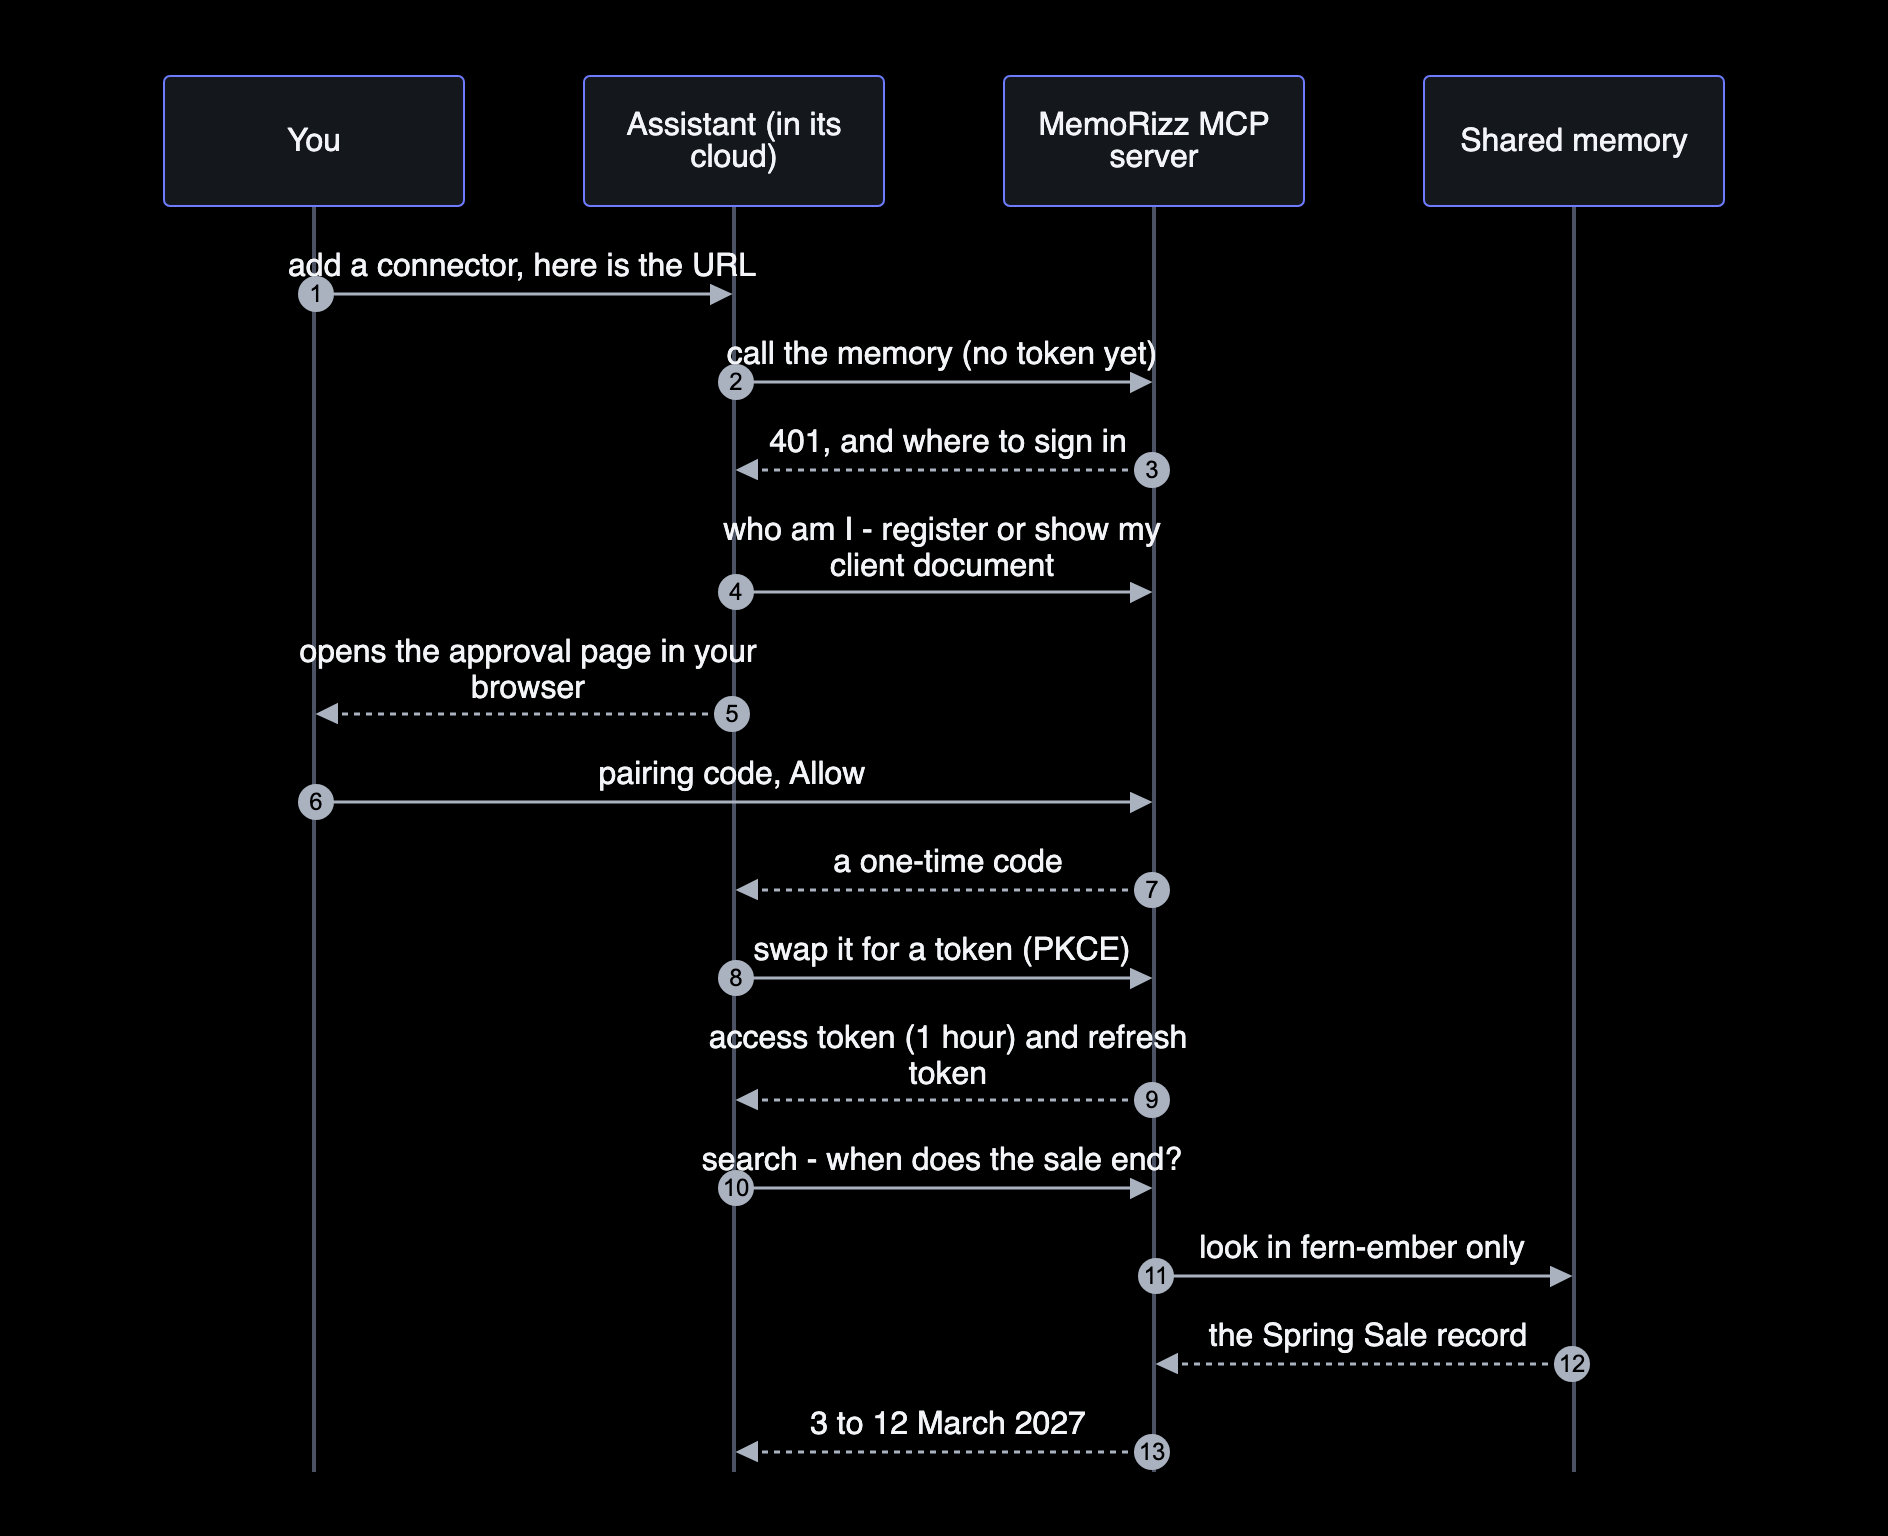

**How to read it.** Steps 2 to 9 are the sign-in, and they happen once per
app. Step 6 is the only one that needs you. Steps 10 to 13 are every
question the assistant asks afterwards.

## Step 1 · Discover

The assistant follows the pointer from the 401 and reads two small
documents: what this resource is, and who signs clients in for it.

In [8]:
resource = web.get("/.well-known/oauth-protected-resource/mcp").json()
signin = web.get("/.well-known/oauth-authorization-server").json()

print("resource:        ", resource["resource"])
print("scopes:          ", resource["scopes_supported"])
print("register at:     ", signin["registration_endpoint"])
print("ask the user at: ", signin["authorization_endpoint"])
print("get a token at:  ", signin["token_endpoint"])
print("client documents:", signin["client_id_metadata_document_supported"])

resource:         http://127.0.0.1:57231/mcp
scopes:           ['memorizz:read', 'memorizz:write']
register at:      http://127.0.0.1:57231/register
ask the user at:  http://127.0.0.1:57231/authorize
get a token at:   http://127.0.0.1:57231/token
client documents: True


Two scopes: read, and save. And two ways for an app to say who it is —
worth knowing, because the real three differ:

| Way | Who uses it | What happens |
|---|---|---|
| **Register** (dynamic client registration) | Muse; Grok Bot sometimes | The app posts its name and callback address and is given a client ID |
| **A client document** | ChatGPT and its dots; Grok Bot | The app's client ID *is* an HTTPS URL to a document describing it, which the server fetches |

MemoRizz accepts both, so you never fill in a "client ID" field in any of
the three apps.

## Step 2 · Say who you are

Pocket registers. The **callback** is the address in the assistant's own
cloud that will receive the result of the sign-in.

In [9]:
CALLBACK = "https://pocket.example/oauth/callback"

app = web.post(
    "/register",
    json={"client_name": "Pocket", "redirect_uris": [CALLBACK], "token_endpoint_auth_method": "none"},
).json()
print("client ID:", app["client_id"][:13] + "…", "| secret:", app.get("client_secret"))

client ID: 1666866b-e853… | secret: None


No secret. Pocket is a *public client*: it proves itself with PKCE, a
one-time secret it makes for each sign-in and never sends until the last
step. A stolen approval is useless without it.

## Step 3 · Ask to be let in

Pocket asks the server to sign it in. The server doesn't decide. It sends
the browser to a page where *you* do.

In [10]:
verifier = secrets.token_urlsafe(48)  # Pocket keeps this
challenge = base64.urlsafe_b64encode(hashlib.sha256(verifier.encode()).digest()).decode().rstrip("=")

asked = web.get(
    "/authorize",
    params={"response_type": "code", "client_id": app["client_id"], "redirect_uri": CALLBACK,
            "code_challenge": challenge, "code_challenge_method": "S256", "state": "pocket-1"},
)
approval_page = asked.headers["location"]
request_id = parse_qs(urlparse(approval_page).query)["request"][0]
print(asked.status_code, "→", approval_page.split("?")[0])

302 → http://127.0.0.1:57231/oauth/approve


## ⭐ Step 4 · You approve, with a pairing code

In real life this is the moment a browser tab opens saying **"Connect
Pocket to your MemoRizz memory?"** with a box for a code.

The code comes from your own computer:

| Command | What it makes |
|---|---|
| `memorizz mcp apps pair --shared` | A code for one app, for ten minutes, that shares your agents' memory |
| `memorizz mcp apps pair --shared --read-only` | The same, for an app that may look but not save |

Here the notebook plays both parts: it makes the code, then submits the
page's form.

In [11]:
pairing = json.loads(memorizz_cli("mcp", "apps", "pair", "--shared", "--json"))

approved = web.post(
    "/oauth/approve",
    data={"request": request_id, "action": "allow", "code": pairing["code"]},
)
back = urlparse(approved.headers["location"])
one_time_code = parse_qs(back.query)["code"][0]
print("sent back to:", f"{back.scheme}://{back.netloc}{back.path}", "| with a one-time code")

sent back to: https://pocket.example/oauth/callback | with a one-time code


The page is on a public address. The code is not. Five wrong codes and the
sign-in is refused; a code that has been used can't be used again.

## Step 5 · Swap the code for a token

Pocket's cloud receives the one-time code at its callback and exchanges
it, presenting the PKCE secret from Step 3.

In [12]:
tokens = web.post(
    "/token",
    data={"grant_type": "authorization_code", "client_id": app["client_id"], "code": one_time_code,
          "redirect_uri": CALLBACK, "code_verifier": verifier},
).json()
token = tokens["access_token"]
print("scope:", tokens["scope"])
print("access token lasts", tokens["expires_in"] // 60, "minutes | refresh token:", "refresh_token" in tokens)

scope: memorizz:read memorizz:write
access token lasts 60 minutes | refresh token: True


An access token for an hour, and a refresh token to get the next one
without bothering you. Both are good for this server's `/mcp` endpoint and
nothing else, and MemoRizz stores only their hashes.

That's the whole of "Add custom connector". Everything after this is the
assistant using its tools.

# Part 5 · The assistant reads

In this part Pocket uses the memory. By the end the question from the
warehouse — when does the sale end? — is answered from the record Mara
wrote in Notebook 1.

**Two helpers**, so the cells below read like what they do.

| Name | What it does |
|---|---|
| `mcp(token, method, params)` | One MCP request to the server, as the app holding `token` |
| `tool(token, name, **arguments)` | Calls one tool and returns its result, or `{"refused": ...}` |

In [13]:
def mcp(token, method, params=None):
    headers = {"Authorization": f"Bearer {token}", "Accept": "application/json, text/event-stream",
               "MCP-Protocol-Version": "2025-06-18"}
    request = {"jsonrpc": "2.0", "id": 1, "method": method, "params": params or {}}
    reply = web.post("/mcp", headers=headers, json=request)
    if reply.status_code != 200:
        return {"refused": reply.status_code}
    events = [line[5:] for line in reply.text.splitlines() if line.startswith("data:")]
    return json.loads(events[0] if events else reply.text)["result"]


def tool(token, name, **arguments):
    result = mcp(token, "tools/call", {"name": name, "arguments": arguments})
    if result.get("isError"):
        return {"refused": result["content"][0]["text"]}
    body = result["structuredContent"]
    return body.get("result", body)

## What the assistant is told

The first thing an MCP client does is say hello, and the server answers
with **instructions**: a paragraph the assistant's model reads before it
uses the tools. This is where the memory introduces itself.

In [14]:
HELLO = {"protocolVersion": "2025-06-18", "capabilities": {}, "clientInfo": {"name": "Pocket", "version": "1"}}

print(textwrap.fill(mcp(token, "initialize", HELLO)["instructions"], width=100))

This is the user's MemoRizz memory, shared with their other apps and agents. Before answering
questions about the user, their work or earlier conversations, search it (search or
memorizz_search_memories). When the user asks you to remember something, or you learn a lasting
fact, decision or preference, save it with memorizz_store_memory (memory_type knowledge_base). Leave
memory_id out unless the user names one, so every app sees the same memories. Never claim a memory
was saved unless the tool returned ok=true. What you save goes to the memory `fern-ember`, which the
user's agents share; search it first.


Search before answering; save lasting facts; say so only if the save
worked. And the last sentence names `fern-ember`, because that's the
memory this server was started for.

## The tools it is given

In [15]:
for listed in mcp(token, "tools/list")["tools"]:
    kind = "reads " if listed["annotations"].get("readOnlyHint") else "WRITES"
    print(kind, listed["name"])

reads  memorizz_server_info
reads  memorizz_list_memories
reads  memorizz_search_memories
reads  memorizz_get_memory
WRITES memorizz_store_memory
WRITES memorizz_forget_memory
WRITES memorizz_update_memory
reads  memorizz_lookup_entities
WRITES memorizz_upsert_entity
reads  memorizz_memory_status
reads  memorizz_list_conversations
reads  memorizz_get_conversation
reads  search
reads  fetch


Fourteen tools, every one about memory. The `reads`/`WRITES` mark is a
hint the server publishes with each tool, and it has teeth: the apps use
it to decide what to ask you about. ChatGPT treats anything not marked
read-only as a write.

`search` and `fetch` are the two a ChatGPT connector must have. The
others let a capable assistant be more exact.

## ⭐ "When does the Spring Sale end?"

In [16]:
found = tool(token, "search", query="When does the Spring Sale end?")["results"]
for row in found[:4]:
    print("-", row["title"])

sale = tool(token, "memorizz_lookup_entities", query="Spring Sale")["entities"][0]
print()
print(sale["name"], "| memory:", sale["memory_id"], "|", {a["name"]: a["value"] for a in sale["attributes"]})

- The Spring Sale runs from 3 through 12 March 2027, inclusive.
- During the Spring Sale, houseplants receive 20% off.
- codex changed pricing.py and its check passed. Asked: Implement sale_price(pric…
- Gift cards and any other category not listed for a discount remain at full pric…

Spring Sale | memory: fern-ember | {'dates': '3–12 March 2027', 'discounts': '20% off all houseplants; 10% off pots', 'exclusions': 'Gift cards excluded'}


There it is: **12 March**, the date Mara changed it to, from the record
she owns — and, if Notebook 2 has run, the findings the coding harnesses
left beside it.

Look at `memory: fern-ember`. The store also holds `mara-only`, a practice
memory from Notebook 1 with the *old* end date in it. Pocket can't see it.
`--memory-id` is why.

> An assistant given the whole store will find your drafts. Give it the
> memory, not the filing cabinet.

# Part 6 · The assistant writes

In this part you tell the assistant something and it keeps it. By the end
the note from the warehouse is in the shop's memory, with the app's name
on it.

**Housekeeping first.** The memory is kept between runs, so a second run
of this notebook would save the same note twice. This removes what its
earlier runs saved and disconnects their apps. It teaches nothing; skip it
on a first read.

In [17]:
OURS = ("Pocket", "Reader")
for row in provider.list_all(MemoryType.KNOWLEDGE_BASE) or []:
    if row.get("created_via") in OURS:
        provider.delete_by_id(row["_id"], MemoryType.KNOWLEDGE_BASE)

for old in json.loads(memorizz_cli("mcp", "apps", "list", "--json")):
    if old["app_name"] in OURS and old["client_id"] != app["client_id"]:
        memorizz_cli("mcp", "apps", "revoke", old["grant_id"])

## ⭐ "Remember this for the team"

One tool call. Notice what Pocket *doesn't* send: a memory ID. It was told
to leave that out, and the server files the note in the memory it was
started for.

In [18]:
NOTE = (
    "From the owner at the ceramics supplier, 26 November 2026: 200 extra pots are "
    "confirmed to arrive on 1 March 2027, in time for the Spring Sale."
)
saved = tool(token, "memorizz_store_memory", content=NOTE)
print(saved)

{'ok': True, 'record_id': '2e4c9a45-f20b-4760-a0c9-47c7eca289ac', 'memory_id': 'fern-ember', 'memory_type': 'knowledge_base'}


**Now open the store and look at the row**, the way we looked at Mara's
record in Notebook 1.

In [19]:
for row in provider.list_all(MemoryType.KNOWLEDGE_BASE) or []:
    if row.get("created_via"):
        print("saved by:", row["created_via"], "| memory:", row["memory_id"])
        print(textwrap.fill(row["content"], width=100))

saved by: Pocket | memory: fern-ember
From the owner at the ceramics supplier, 26 November 2026: 200 extra pots are confirmed to arrive on
1 March 2027, in time for the Spring Sale.


`saved by: Pocket`. Every record an app writes carries the app's name, and
the store's change history (Notebook 1, Part 9) records it too. When
something odd turns up in the shared memory, "which assistant wrote that?"
has an answer.

The note is knowledge, not an entity record: Pocket added a fact, it
didn't rewrite Mara's decision. Few writers, many readers still holds.

# Part 7 · Back to the team

This is the part the three notebooks have been walking towards. You told
your phone something at a warehouse. By the end, a support agent and a
coding harness both know it — and nobody forwarded anything.

## ⭐ Sam, a MemAgent

Sam is the support agent from Notebook 1, loaded exactly as it left him.
He has never heard of Pocket.

In [20]:
from memorizz import MemAgent

saved_agents = {agent.name: agent.agent_id for agent in provider.list_memagents()}
sam = MemAgent.load(saved_agents["Sam"], memory_provider=provider)

QUESTION = "A customer asks whether we'll have enough pots during the Spring Sale. Is anything confirmed?"
say(sam.name, sam.run(QUESTION, memory_id=TEAM, thread_id="sam-pots"))

Sam: Yes. We have 200 extra pots confirmed to arrive on 1 March, ahead of the Spring Sale. We can’t
    guarantee that will be enough for everyone, though.



Two hundred pots, 1 March. Sam retrieved the note the same way he
retrieves the handbook: it's knowledge, in his memory.

## A coding harness

And the third kind of agent. If a harness from Notebook 2 is installed, we
ask it too, read-only, in the shop's code workspace.

In [21]:
from memorizz import MetaHarness

SHOP = STORE.parent / "fern_ember_shop"
meta = MetaHarness.from_env(memory_provider=provider, allowed_workspace_roots=[str(SHOP)])
ready = [h["name"] for h in meta.list_harnesses() if h["ready"]]
harness = next((name for name in ("pi", "claude-code", "codex") if name in ready), None)

ASK = "From the team's memory: is there news about stock that matters for the Spring Sale? Two lines. Do not edit files."
if harness and SHOP.exists():
    result = meta.run({"task": ASK, "workspace": str(SHOP), "harness": harness, "memory_id": TEAM})
    say(harness, result.final_response)
else:
    print("No harness ready here (or Notebook 2 has not run); skipping.")
meta.close()

pi: Yes. The ceramics supplier's owner said on 26 Nov 2026 that 200 extra pots are confirmed to
    arrive on 1 March 2027, in time for the Spring Sale (which runs 3–12 March 2027)
    [memory:knowledge_base:2e4c9a45-f20b-4760-a0c9-47c7eca289ac]. Memory doesn't say how many pots
    are in stock overall or whether 200 is enough for the sale, so I wouldn't promise more than that
    confirmed delivery.



Follow the note:

1. **You** said it to an assistant, at a warehouse.
2. **The assistant** (a vendor's app, in a vendor's cloud) saved it over
   MCP.
3. **Sam** (a MemAgent) told a customer.
4. **A coding harness** (another vendor's CLI) cited it.

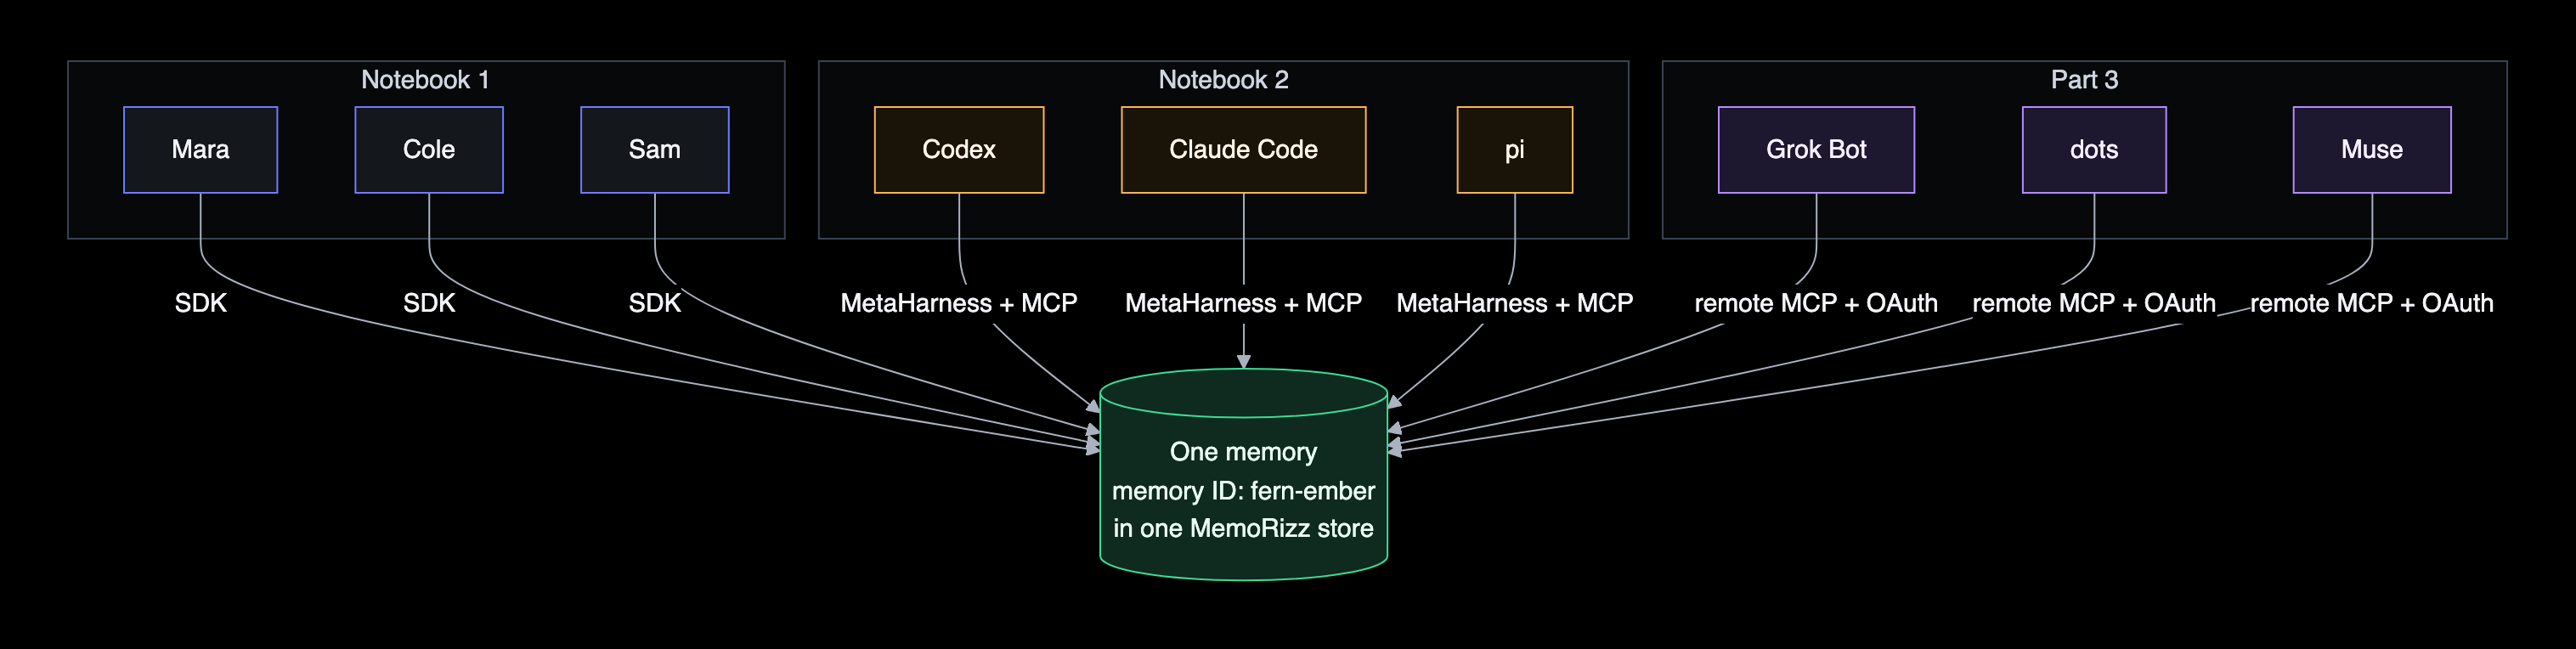

That is the picture from the end of Notebook 1, and every arrow on it has
now carried something.

# Part 8 · Who is connected

A door needs a list of who has a key. In this part we look at the list,
connect an assistant that may only read, and take a key back. By the end
you'll have seen each control work.

## The list

In [22]:
def connected():
    for grant in json.loads(memorizz_cli("mcp", "apps", "list", "--json")):
        print(f"{grant['grant_id']}  {grant['app_name']:<8} {', '.join(grant['scopes'])}")


connected()

app_63a83920834a4083  Pocket   memorizz:read, memorizz:write


## ⭐ An assistant that may look but not touch

Not every assistant should hold the pen. `connect()` is Part 4 as one
function: register, ask, approve with a fresh pairing code, swap for a
token. The pairing code decides what the app may do.

In [23]:
def connect(name, *pair_options):
    client = web.post("/register", json={"client_name": name, "redirect_uris": [CALLBACK],
                                         "token_endpoint_auth_method": "none"}).json()
    secret = secrets.token_urlsafe(48)
    proof = base64.urlsafe_b64encode(hashlib.sha256(secret.encode()).digest()).decode().rstrip("=")
    ask = {"response_type": "code", "client_id": client["client_id"], "redirect_uri": CALLBACK,
           "code_challenge": proof, "code_challenge_method": "S256", "state": name}
    request = parse_qs(urlparse(web.get("/authorize", params=ask).headers["location"]).query)["request"][0]
    code = json.loads(memorizz_cli("mcp", "apps", "pair", *pair_options, "--json"))["code"]
    done = web.post("/oauth/approve", data={"request": request, "action": "allow", "code": code})
    grant = {"grant_type": "authorization_code", "client_id": client["client_id"], "redirect_uri": CALLBACK,
             "code": parse_qs(urlparse(done.headers["location"]).query)["code"][0], "code_verifier": secret}
    return web.post("/token", data=grant).json()["access_token"]

In [24]:
reader = connect("Reader", "--shared", "--read-only")

print("reads: ", tool(reader, "search", query="200 extra pots arriving on 1 March")["results"][0]["title"])
print("writes:", tool(reader, "memorizz_store_memory", content="The sale now ends on 31 March."))

reads:  From the owner at the ceramics supplier, 26 November 2026: 200 extra pots are c…
writes: {'refused': 'Error executing tool memorizz_store_memory: insufficient_scope: This operation requires the memorizz:write scope'}


It found the note and couldn't add one. That refusal is the server's, not
the assistant's good manners: a read-only pairing has no write scope,
whatever the model on the other end is talked into.

## Taking a key back

`revoke` disconnects one app. Its tokens stop working at once.

In [25]:
grants = json.loads(memorizz_cli("mcp", "apps", "list", "--json"))
pocket = next(g for g in grants if g["app_name"] == "Pocket")

print(memorizz_cli("mcp", "apps", "revoke", pocket["grant_id"]).strip())
print("Pocket's next call:", mcp(token, "tools/list"))
connected()

Disconnected Pocket.
Pocket's next call: {'refused': 401}


app_8f6d5bee9aed4a73  Reader   memorizz:read


A 401, with the token Pocket was happily using a minute ago. To come back
it would need a new pairing code, which only you can make.

# Part 9 · Going public

Everything so far ran on `127.0.0.1`. Muse, Grok Bot and dots call from
their own clouds, so in this part we stop the local server and get the
command for a public one. By the end you'll have one line to run in a
terminal.

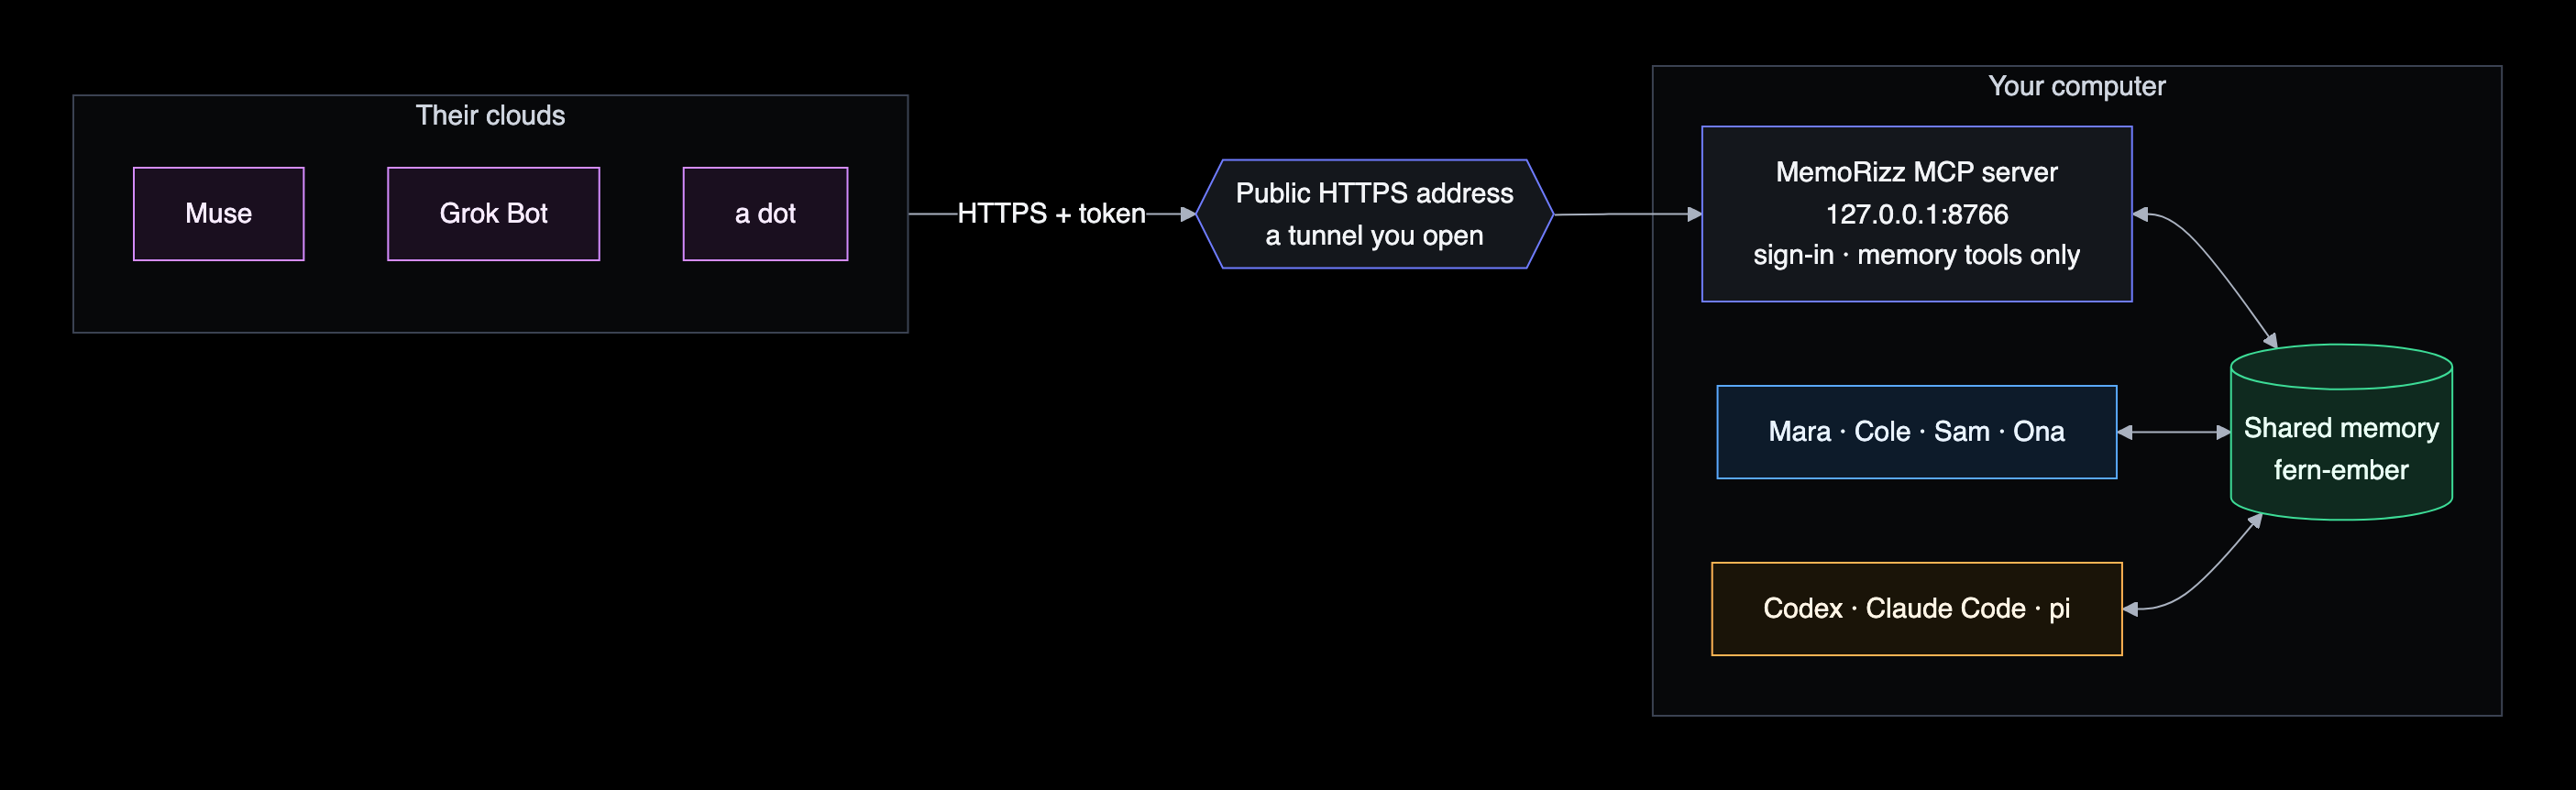

**How to read it.** The server still listens only on `127.0.0.1`. A tunnel
gives it an HTTPS address and carries requests to it. Anyone can reach the
address; only an app you approved can use the memory. Your agents and
harnesses keep reading the store directly, as before.

## Pick a tunnel

| Tunnel | Command | The address | Good for |
|---|---|---|---|
| **Tailscale Funnel** | `tailscale funnel --bg 8766` | `https://your-mac.your-tailnet.ts.net`, fixed | Apps stay connected across restarts. Best for a live demo |
| **ngrok** | `ngrok http 8766` | Random on the free plan, or a reserved domain | Quick, and xAI names it in its own docs |
| **Cloudflare quick tunnel** | `memorizz mcp apps serve --tunnel …` | Random, new each start | No account. Apps must be reconnected each time |

Open the tunnel yourself, in a terminal: it is the one step that puts
something of yours on the internet, and it should be you who does it.

In [26]:
server.terminate()  # the loopback server from Part 3


def serve_command(public_url="https://YOUR-ADDRESS"):
    here = {"MEMORIZZ_HOME": f"$PWD/{HOME.name}", "MEMORIZZ_MEMORY_ROOT": f"$PWD/{STORE.name}"}
    settings = {"OPENAI_API_KEY": "$OPENAI_API_KEY", **SERVER_ENV, **here}
    env = " ".join(f"{name}={value}" for name, value in settings.items())
    return f"{env} memorizz mcp apps serve --shared --memory-id {TEAM} --public-url {public_url}"


print(serve_command())

OPENAI_API_KEY=$OPENAI_API_KEY MEMORIZZ_BACKEND=filesystem MEMORIZZ_MEMORY_ROOT=$PWD/fern_ember_store MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 MEMORIZZ_HOME=$PWD/fern_ember_home memorizz mcp apps serve --shared --memory-id fern-ember --public-url https://YOUR-ADDRESS


Run that from this notebook's folder, with your tunnel's address in place
of `https://YOUR-ADDRESS` (a bare origin, no path). It prints the **server URL**, which ends in `/mcp`,
and the first **pairing code**. Keep it running. For each further app:

```bash
MEMORIZZ_HOME=… memorizz mcp apps pair --shared            # may save
MEMORIZZ_HOME=… memorizz mcp apps pair --shared --read-only # may only read
```

`MEMORIZZ_HOME` matters: pairing codes live there, so the `pair` command
must use the same one as the server.

# Part 10 · Muse, Grok Bot and a dot

This part is the clicks. Each app does what Pocket did in Part 4; what
differs is where you paste the URL and what the app is allowed to do
afterwards. By the end all three can answer "when does our Spring Sale
end?" from the same record.

For each one you need the **server URL** and a **fresh pairing code**.

## At a glance

| | Muse (Meta) | Grok Bot (xAI) | A dot (OpenAI) |
|---|---|---|---|
| **Where you add it** | Ask Muse, in chat | Connect apps → Add a custom connector | ChatGPT on the web → Plugins → + |
| **How it says who it is** | Registers itself | Cursor's client document, or registers | ChatGPT's client document, signed |
| **Fields you fill in** | The URL | Name, the URL | The URL, OAuth |
| **Can it save?** | Yes; it asks you before each write | Yes; you set each tool to allow, review, ask or block | **Depends on your plan** — see below |
| **What MemoRizz calls it** | Muse | Grok Bot | ChatGPT |

## ⭐ Muse

Muse adds connectors by being asked.

1. In Muse, say: *"Create a custom connector for a remote MCP server at
   `https://YOUR-ADDRESS/mcp`. It uses OAuth."*
2. Muse confirms, then opens MemoRizz's approval page. Type the pairing
   code and choose **Allow**.
3. Ask: *"Using the memorizz connector, when does our Spring Sale end?"*

Be ready for two things. Muse **asks before each write**, so "remember
that 200 pots arrive on 1 March" produces a confirmation first. And Meta
documents custom connectors thinly: the route above is what works at the
time of writing, and the wording may change. If the sign-in page never
opens, ask Muse to "connect" or "sign in to" the connector.

## ⭐ Grok Bot

1. In Grok Bot, open **Connect apps** and choose **Add a custom
   connector**.
2. Name it `memorizz`, keep the type **Remote HTTPS**, paste the server
   URL. Leave the OAuth client ID and secret empty.
3. On MemoRizz's approval page, type a pairing code and choose **Allow**.
4. In the connector's tool list, set the read tools to **Always allow**
   and leave the write tools on **Needs approval**.

Grok Bot's connectors run on the Bot's own cloud computer, not on your
Mac, which is why even a Bot sitting on your laptop needs the public
address. It signs in under Cursor's name (Cursor builds the app);
MemoRizz recognises it from where the sign-in returns to and lists it as
Grok Bot.

## ⭐ A dot

A dot has no connector form of its own. It uses the plugins in your
ChatGPT account.

1. In ChatGPT **on the web**, go to **Plugins → + → Add custom MCP
   server**, paste the server URL, choose **OAuth**, and create it as a
   plugin. (If you don't see the option, turn on Developer mode in
   settings.)
2. On MemoRizz's approval page, type a pairing code and choose **Allow**.
3. Open your dot → **Customize → Plugins** and check the plugin is on.
4. Ask the dot: *"When does our Spring Sale end?"*

**The plan gate.** OpenAI decides what a custom server may do on each
plan. At the time of writing its help pages say full access, including
writes, is for Business, Enterprise and Edu, and that Pro can only search
and fetch. If your dot can find the sale but won't save the pots note,
that is the plan, not your setup — and a read-only dot is still a dot
that knows when the sale ends.

## What to say, in any of them

| Say | What should happen | What it proves |
|---|---|---|
| "When does our Spring Sale end, and what's excluded?" | 12 March 2027; gift cards | It reads Mara's record (Notebook 1) |
| "Is the sale in the shop's code yet? Was it checked?" | Implemented, check passed | It reads what the harnesses left (Notebook 2) |
| "Remember for the team: the supplier confirmed 200 extra pots for 1 March." | A save, perhaps after a confirmation | It writes to the shared memory |
| Then, in the MemoRizz console, ask **Sam**: "Will we have enough pots?" | Sam cites the note | The loop closes |

# Part 11 · See it in the UI

Start the console as in Notebooks 1 and 2 (the command is printed below)
and look at three things:

| Where | What you'll see |
|---|---|
| **Settings → Connected apps** | Every app you approved, what it may do, when it last called, and a button to disconnect it. Pairing codes can be made here too |
| **Memory types → Shared → `fern-ember`** | Mara, Cole, Sam and Ona; Codex, Claude Code and pi; and the apps that have saved here. The whole cast of three notebooks on one page |
| **Memory types → Knowledge base** | The pots note, with the app that saved it |

In [27]:
def ui_command(port=8765):
    return (
        f"MEMORIZZ_HOME=$PWD/{HOME.name} "
        "MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai "
        "MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small "
        "MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 "
        f"memorizz ui --backend filesystem --path $PWD/{STORE.name} --port {port}"
    )


print(ui_command())

MEMORIZZ_HOME=$PWD/fern_ember_home MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 memorizz ui --backend filesystem --path $PWD/fern_ember_store --port 8765


# Part 12 · Trade-offs

Giving an assistant a door to your team's memory is the most useful thing
in these three notebooks and the one to be most careful with.

## When to connect an assistant, and when not to

| Connect it when | Don't when |
|---|---|
| You make and need decisions away from your desk | The memory holds things the vendor's cloud shouldn't process |
| What you learn on the road should reach your agents | The assistant only needs it once: paste it |
| You can name the one memory it should see | You'd have to give it the whole store to be useful |

## What it costs

- **Your memory's content goes to the assistant's vendor.** Whatever a
  tool returns is read by Meta's, xAI's or OpenAI's model. A memory ID is
  the right size of thing to decide that about. A whole store is not.
- **A public address is an attack surface.** The sign-in is what protects
  it: pairing codes, one-hour tokens, PKCE, hashes at rest. Keep the
  server to memory tools (it always is, here) and stop it when the demo
  ends.
- **A reader of the shared memory reads everything every writer wrote.**
  If an agent saves text from a web page or an email, an assistant may
  later read it as fact. This is the Notebook 1 lesson with higher stakes:
  few writers, labelled writes, read-only where you can.
- **An assistant that can write can be talked into writing.** Prefer the
  app's own per-write approval (Muse and Grok Bot have one), pair
  read-only when an assistant only needs answers, and check `saved by`
  when something looks off.
- **Your laptop is now a server.** Close the lid and the assistants get
  errors. For anything past a demo the memory belongs in a database, on a
  host that stays up.
- **You don't control the client.** Which tools an assistant calls, and
  when, is its model's decision, and each vendor changes its connector
  rules on its own schedule. The plan gate on dots is today's example.

> The address is public. The memory isn't. Everything in this notebook is
> the difference between those two sentences.

## ⭐ One memory, three kinds of agent

Three notebooks, one folder, one memory ID.

1. **Agents you built** shared it: Mara wrote a decision, Cole and Sam
   read it.
2. **Agents you didn't build** shared it: three coding harnesses turned
   the decision into checked code, and left what they found.
3. **Agents you only configure** shared it: an assistant in someone
   else's cloud read the decision and added a note.

Nothing was synced, exported or sent between any two of them. Each one
was given the same place to look.

The memory doesn't move. The agents come to it.

## FAQ

1. **Do I have to install anything in Muse, Grok Bot or ChatGPT?** No.
   Each takes a URL. MemoRizz is the server; the apps are ordinary MCP
   clients.
2. **Why can't I just use `http://localhost`?** The assistants run in
   their vendors' clouds, and from there `localhost` is their computer,
   not yours. Grok refuses private addresses outright.
3. **Is a pairing code a password?** No. It works once, for one app, for
   ten minutes, and it only matters on the approval page. Afterwards the
   app holds a token you can revoke.
4. **What exactly can a connected app do?** Use the memory tools: search,
   read, save, entities, conversations. It can propose deleting a memory,
   which happens only after you approve it on your computer. It can't run
   agents, harnesses or commands.
5. **Does the assistant stop using its own memory?** No, and it shouldn't.
   Its memory is about you: how you like answers, what you asked last
   week. The shared memory is about the work. Good assistants use both.
6. **Can two assistants see what each other saved?** Yes, if both were
   paired with `--shared` on the same server. That's the point: what you
   tell Muse, your dot can find.
7. **Why did my dot read but refuse to save?** Most likely your ChatGPT
   plan. See the plan gate in Part 10.
8. **Can I use this without `--memory-id`?** Yes. Then a shared app can
   read every memory your local agents keep and saves to one called
   `personal`. That suits an assistant that should know everything you
   work on. For a team's memory, name the memory.
9. **Where should this run for real?** Not on a laptop. Put the store in
   a database, run the server on a host with a fixed address, and keep the
   same sign-in.